# MovieLens Latest Small — local data exploration

This notebook analyzes the actual Kaggle dataset `grouplens/movielens-latest-small`. Only `ratings.csv` and `movies.csv` are analytical inputs. The original download archive, publisher README, ancillary CSVs and SHA256 provenance remain intact under `data/raw/ml-latest-small/`.

The analysis uses read-only **in-memory DuckDB SQL**, Pandas and Matplotlib. It creates no final split files, trains no model, initializes no DVC/MLflow service and uses no cloud or GPU. Run with the Phase 1 environment from `requirements-eda.txt`.

Ratings are **submission events**, not verified viewing/exposure logs. `rating >= 4.0` is an observed-positive convention; low ratings and unobserved pairs are distinct. Absence is not a verified dislike.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import importlib.metadata

start = Path(os.environ.get("RECSYS_PROJECT_DIR", Path.cwd())).resolve()
ROOT = next((p for p in [start, *start.parents] if (p / "src" / "recsys").is_dir() and (p / "README.md").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Start Jupyter in this repository, or set RECSYS_PROJECT_DIR.")
DATA_DIR = Path(os.environ.get("MOVIELENS_SMALL_DATA_DIR", ROOT / "data/raw/ml-latest-small")).resolve()
if "recsys" in sys.modules and not Path(sys.modules["recsys"].__file__).resolve().is_relative_to(ROOT / "src"):
    raise RuntimeError("A different recsys package is cached. Restart the kernel and use this repository's src/.")
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import duckdb
from IPython.display import display, Markdown
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
from recsys.small_data import verify_provenance, sha256
from recsys.small_eda import analysis_connection, cutoff_options, split_feasibility

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "font.size": 10})
pd.set_option("display.max_columns", 40)
VERSIONS = {name: importlib.metadata.version(name) for name in ["numpy", "pandas", "duckdb", "matplotlib"]}
print("Repository:", ROOT)
print("Raw data:", DATA_DIR)
print("Versions:", VERSIONS)

Matplotlib is building the font cache; this may take a moment.


Repository: /Users/vincent/Documents/projects/hybrid_recsys
Raw data: /Users/vincent/Documents/projects/hybrid_recsys/data/raw/ml-latest-small
Versions: {'numpy': '2.4.4', 'pandas': '3.0.2', 'duckdb': '1.5.2', 'matplotlib': '3.11.2'}


## 1. Provenance, schema and data quality

Acquisition is separate from EDA: `python tools/download_movielens_small.py`. Loading verifies the manifest's source identity, every recorded file size/hash and the required CSV schemas. Validation rejects missing values, invalid IDs/ratings/timestamps, duplicate user–movie pairs and broken movie references; it never repairs or deletes source rows silently.

The public Kaggle CLI download succeeded anonymously. The separate metadata command required login, so a Kaggle version number is unavailable and is **not inferred** from archive timestamps. The bundled publisher generation date and content hashes identify this snapshot. Consult the unmodified bundled README for licence and citation conditions; the Kaggle label `other` is not a CC0 assertion.

In [2]:
manifest = verify_provenance(DATA_DIR)
con, quality = analysis_connection(DATA_DIR)
print("Source:", manifest["source"]["dataset_id"])
print("Download UTC:", manifest["downloaded_at_utc"])
print("Kaggle version:", manifest["source"]["kaggle_dataset_version"])
print("Publisher generation date:", manifest["source"]["publisher_generated_date"])
print("Licence reference:", manifest["licence"])
display(pd.DataFrame(manifest["files"]).T[["bytes", "sha256"]])
display(pd.DataFrame([quality]))
print("Publisher expected counts:", manifest["publisher_expected_counts"])
print("Count discrepancies:", manifest["discrepancies"])
display(con.sql("DESCRIBE ratings").df())
display(con.sql("DESCRIBE movies").df())
display(con.sql("SELECT * FROM ratings ORDER BY userId, timestamp, movieId LIMIT 5").df())
display(con.sql("SELECT * FROM movies ORDER BY movieId LIMIT 5").df())

Source: grouplens/movielens-latest-small
Download UTC: 2026-10-27T15:53:42.683065+00:00
Kaggle version: None
Publisher generation date: September 26, 2018
Licence reference: {'kaggle_label': 'other', 'reference': 'README.md', 'notice': 'Keep and consult the original bundled publisher README licence/citation conditions; not a CC0 assumption.'}


,bytes,sha256
README.md,8342,63d22ac138e80fae37021797ed8e1b9424b5239dc576a1...
_source/kaggle-download.zip,993937,12b11d77fdb2c221daa631e5724104f51ecab1298c0e5f...
links.csv,197979,97ad18e4e56a09363c65676b6cb3482ce3e2cea2372a24...
movies.csv,494431,5a5f32dd9bb3797b8e728a1b98958789d2b13f294a69fd...
ratings.csv,2483723,aa289ca83157595d0df6aea1be6a4ded676ddc4385472e...
tags.csv,118660,92a9f8bb7916dceef6151209845788c3643f794dfa79d1...


,passed,missing_values,duplicate_user_movie_pairs,duplicate_movie_ids,unknown_movie_ratings,ratings,metadata_movies,users,rated_movies,metadata_movies_without_ratings,observed_positive_ratings,positive_definition,observed_low_ratings,rating_min,rating_max,timestamp_min,timestamp_max,timestamp_min_utc,timestamp_max_utc
0,True,"{'ratings': {'userId': 0, 'movieId': 0, 'ratin...",0,0,0,100836,9742,610,9724,18,48580,rating >= 4.0,52256,0.5,5.0,828124615,1537799250,1996-03-29T18:36:55+00:00,2018-09-24T14:27:30+00:00


Publisher expected counts: {'ratings': 100836, 'metadata_movies': 9742, 'users': 610}
Count discrepancies: {}


,column_name,column_type,null,key,default,extra
0,userId,INTEGER,YES,None,None,None
1,movieId,INTEGER,YES,None,None,None
2,rating,FLOAT,YES,None,None,None
3,timestamp,BIGINT,YES,None,None,None


,column_name,column_type,null,key,default,extra
0,movieId,INTEGER,YES,None,None,None
1,title,VARCHAR,YES,None,None,None
2,genres,VARCHAR,YES,None,None,None


,userId,movieId,rating,timestamp
0,1,804,4.0,964980499
1,1,1210,5.0,964980499
2,1,2018,5.0,964980523
3,1,2628,4.0,964980523
4,1,2826,4.0,964980523


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [3]:
quality_sql = con.sql("""
SELECT 'ratings' AS input, count(*) AS rows,
       count(*) FILTER (WHERE userId IS NULL OR movieId IS NULL OR rating IS NULL OR timestamp IS NULL) AS null_rows
FROM ratings
UNION ALL
SELECT 'movies', count(*), count(*) FILTER (WHERE movieId IS NULL OR title IS NULL OR genres IS NULL)
FROM movies
""").df()
display(quality_sql)
assert quality["passed"] and quality_sql.null_rows.sum() == 0
assert quality["ratings"] == manifest["files"]["ratings.csv"]["rows"]
assert quality["metadata_movies"] == manifest["files"]["movies.csv"]["rows"]

,input,rows,null_rows
0,ratings,100836,0
1,movies,9742,0


## 2. Ratings and observed-positive convention

The threshold is descriptive and explicit: **observed positive** means a submitted rating at least 4.0. An observed low rating is below 4.0. Unobserved pairs have no rating label; their eventual use as training contrasts requires a documented weak-supervision convention. These frequencies are not exposure-weighted preference probabilities.

,rating,ratings,share
0,0.5,1370,0.013586
1,1.0,2811,0.027877
2,1.5,1791,0.017762
3,2.0,7551,0.074884
4,2.5,5550,0.055040
5,3.0,20047,0.198808
6,3.5,13136,0.130271
7,4.0,26818,0.265957
8,4.5,8551,0.084801
9,5.0,13211,0.131015


,observed_ratings,observed_positive,observed_low,positive_share
0,100836,48580,52256,0.481772


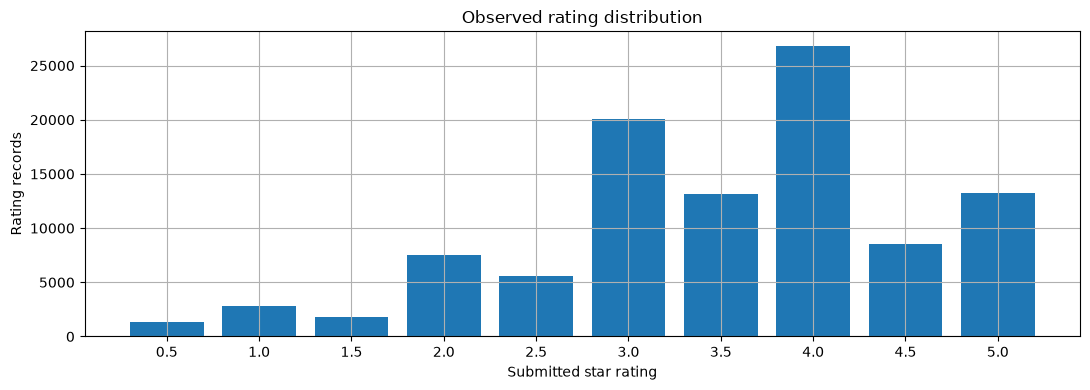

In [4]:
rating_distribution = con.sql("""
SELECT rating, count(*) AS ratings,
       count(*) * 1.0 / sum(count(*)) OVER () AS share
FROM ratings GROUP BY rating ORDER BY rating
""").df()
display(rating_distribution)
positive_summary = con.sql("""
SELECT count(*) AS observed_ratings,
       count(*) FILTER (WHERE rating >= 4.0) AS observed_positive,
       count(*) FILTER (WHERE rating < 4.0) AS observed_low,
       avg(CASE WHEN rating >= 4.0 THEN 1.0 ELSE 0.0 END) AS positive_share
FROM ratings
""").df()
display(positive_summary)
fig, ax = plt.subplots()
ax.bar(rating_distribution.rating.astype(str), rating_distribution.ratings)
ax.set(xlabel="Submitted star rating", ylabel="Rating records", title="Observed rating distribution")
plt.tight_layout(); plt.show()

## 3. User activity and cold-history statistics

The source was selected to include users with at least 20 ratings over their complete recorded history. That does **not** imply that a user has history before an exploratory training cutoff. Never use complete-history counts as temporal training features. Zero-history users outside this observed dataset cannot be enumerated from ratings alone.

Exploratory positive-history cohorts below use 0, 1–4, 5–19 and 20+ observed positives. They are reporting conventions, not a frozen evaluation protocol.

,count,mean,std,min,10%,25%,50%,75%,90%,99%,max
n_ratings,610.0,1.653049e+02,2.694806e+02,20.0,24.0,35.00,70.5,168.00,400.3,1.256220e+03,2698.0
n_positive,610.0,7.963934e+01,1.093236e+02,0.0,13.0,21.00,40.0,91.75,200.2,5.501300e+02,1227.0
span_seconds,610.0,2.024310e+07,6.470750e+07,38.0,369.0,883.25,4688.5,3352506.00,53271429.1,3.617982e+08,566541856.0


,cohort,users
0,0: no positive history,1
1,1: 1–4 positives,6
2,2: 5–19 positives,138
3,3: 20+ positives,465


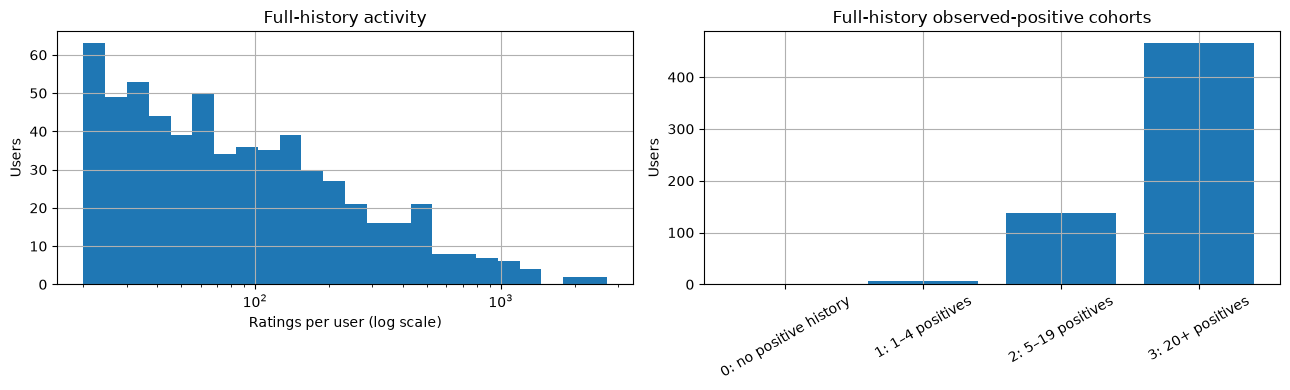

In [5]:
con.execute("""
CREATE OR REPLACE TEMP VIEW user_activity AS
SELECT userId, count(*) AS n_ratings,
       count(*) FILTER (WHERE rating >= 4) AS n_positive,
       min(timestamp) AS first_timestamp, max(timestamp) AS last_timestamp,
       max(timestamp) - min(timestamp) AS span_seconds
FROM ratings GROUP BY userId
""")
users = con.sql("SELECT * FROM user_activity ORDER BY userId").df()
display(users[["n_ratings", "n_positive", "span_seconds"]].describe(percentiles=[.1, .25, .5, .75, .9, .99]).T)
user_cohorts = con.sql("""
SELECT CASE WHEN n_positive=0 THEN '0: no positive history'
            WHEN n_positive<5 THEN '1: 1–4 positives'
            WHEN n_positive<20 THEN '2: 5–19 positives' ELSE '3: 20+ positives' END AS cohort,
       count(*) AS users
FROM user_activity GROUP BY cohort ORDER BY cohort
""").df()
display(user_cohorts)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(users.n_ratings, bins=np.geomspace(max(1, users.n_ratings.min()), users.n_ratings.max()+1, 25))
axes[0].set(xscale="log", xlabel="Ratings per user (log scale)", ylabel="Users", title="Full-history activity")
axes[1].bar(user_cohorts.cohort, user_cohorts.users)
axes[1].tick_params(axis="x", labelrotation=30)
axes[1].set(ylabel="Users", title="Full-history observed-positive cohorts")
plt.tight_layout(); plt.show()

## 4. Item popularity, long tail and genres

Include metadata movies with zero ratings in catalog statistics. Popularity here uses all submitted ratings and also reports positive counts separately. Genres are multi-label; summing per-genre interactions double-counts multi-genre movies. `(no genres listed)` is an explicit metadata sentinel, not an inferred content feature. Full-dataset popularity/genres below are descriptive EDA, not temporally valid model features.

,movieId,title,genres,n_ratings,n_positive
0,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329,249
1,318,"Shawshank Redemption, The (1994)",Crime|Drama,317,274
2,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307,244
3,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279,225
4,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278,222
5,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251,201
6,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238,145
7,110,Braveheart (1995),Action|Drama|War,237,166
8,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224,150
9,527,Schindler's List (1993),Drama|War,220,175


Metadata movies without ratings: 18
Share of ratings in the most-rated 10% of metadata movies: 0.6010254274267127


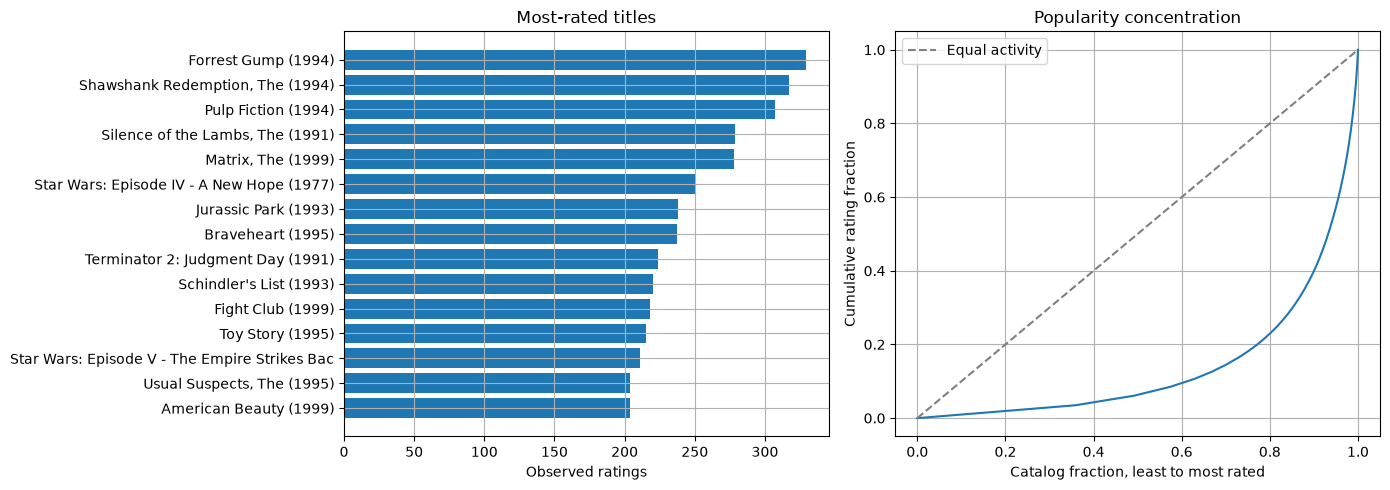

In [6]:
con.execute("""
CREATE OR REPLACE TEMP VIEW item_activity AS
SELECT m.movieId, m.title, m.genres, count(r.userId) AS n_ratings,
       count(r.userId) FILTER (WHERE r.rating >= 4) AS n_positive
FROM movies m LEFT JOIN ratings r USING (movieId)
GROUP BY m.movieId, m.title, m.genres
""")
items = con.sql("SELECT * FROM item_activity ORDER BY n_ratings DESC, movieId").df()
display(items.head(15))
print("Metadata movies without ratings:", int(items.n_ratings.eq(0).sum()))
ranked_counts = items.n_ratings.to_numpy()
top_decile_n = int(np.ceil(len(items) * .1))
print("Share of ratings in the most-rated 10% of metadata movies:", ranked_counts[:top_decile_n].sum() / ranked_counts.sum())
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(items.head(15).title.str.slice(0, 45)[::-1], items.head(15).n_ratings[::-1])
axes[0].set(xlabel="Observed ratings", title="Most-rated titles")
axes[1].plot(np.arange(1, len(items)+1) / len(items), np.cumsum(np.sort(ranked_counts)) / ranked_counts.sum())
axes[1].plot([0, 1], [0, 1], "--", color="grey", label="Equal activity")
axes[1].set(xlabel="Catalog fraction, least to most rated", ylabel="Cumulative rating fraction", title="Popularity concentration")
axes[1].legend()
plt.tight_layout(); plt.show()

,genre,movies,rating_memberships,positive_memberships
0,Drama,4361,41928.0,22927.0
1,Comedy,3756,39053.0,16882.0
2,Thriller,1894,26452.0,12537.0
3,Action,1828,30635.0,13896.0
4,Romance,1596,18124.0,8668.0
5,Adventure,1263,24161.0,11569.0
6,Crime,1199,16681.0,9077.0
7,Sci-Fi,980,17243.0,8014.0
8,Horror,978,7291.0,2893.0
9,Fantasy,779,11834.0,5546.0


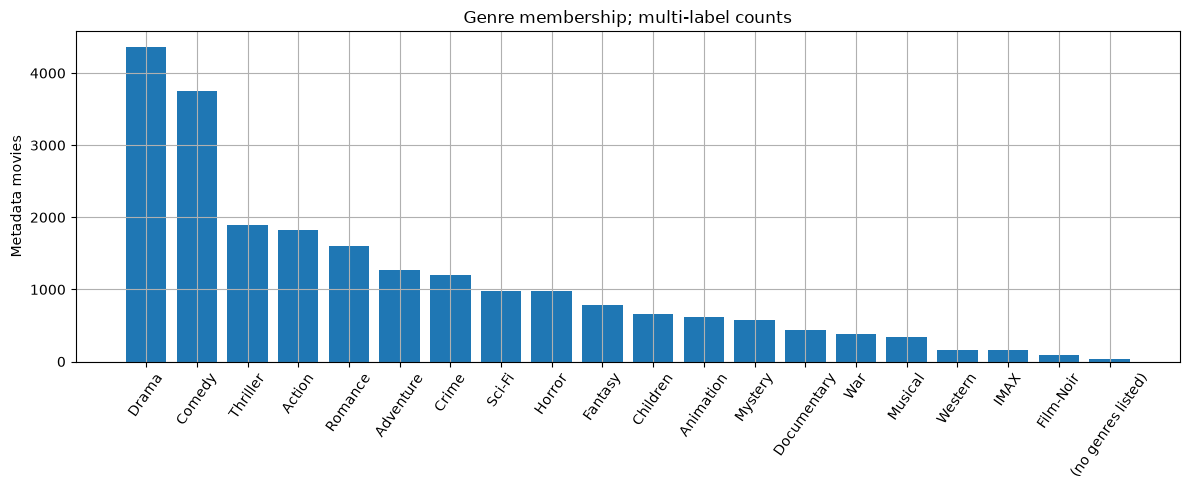

In [7]:
genres = con.sql("""
WITH expanded AS (
 SELECT movieId, unnest(string_split(genres, '|')) AS genre FROM movies
)
SELECT g.genre, count(DISTINCT g.movieId) AS movies,
       sum(a.n_ratings) AS rating_memberships, sum(a.n_positive) AS positive_memberships
FROM expanded g JOIN item_activity a USING (movieId)
GROUP BY g.genre ORDER BY movies DESC, genre
""").df()
display(genres)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(genres.genre, genres.movies)
ax.tick_params(axis="x", labelrotation=55)
ax.set(ylabel="Metadata movies", title="Genre membership; multi-label counts")
plt.tight_layout(); plt.show()

## 5. Interaction sparsity

Compute arithmetic counts rather than materializing a dense user×movie matrix. A unique observed pair counts as one interaction. Unobserved entries are unknown; sparsity is not a verified negative-feedback rate.

In [8]:
sparsity = con.sql("""
WITH n AS (
 SELECT count(*) AS interactions, count(DISTINCT userId) AS users,
        count(DISTINCT movieId) AS rated_movies FROM ratings
), m AS (SELECT count(*) AS metadata_movies FROM movies)
SELECT *, users * metadata_movies AS possible_metadata_pairs,
       interactions * 1.0 / (users * metadata_movies) AS observed_density,
       1.0 - interactions * 1.0 / (users * metadata_movies) AS sparsity,
       users * metadata_movies - interactions AS unobserved_pairs
FROM n CROSS JOIN m
""").df()
display(sparsity)

,interactions,users,rated_movies,metadata_movies,possible_metadata_pairs,observed_density,sparsity,unobserved_pairs
0,100836,610,9724,9742,5942620,0.016968,0.983032,5841784


## 6. Submission-time distribution

All dates are UTC. These are timestamps of rating submissions, not necessarily when a movie was watched. The dataset spans changing user populations and collection regimes. A large global time range does not mean each user was observed throughout it.

,month,ratings,active_users,positives
0,1996-03-01 00:00:00+00:00,58,1,42
1,1996-04-01 00:00:00+00:00,165,4,102
2,1996-05-01 00:00:00+00:00,832,14,401
3,1996-06-01 00:00:00+00:00,883,15,426
4,1996-07-01 00:00:00+00:00,489,12,269


Submission range UTC: 1996-03-29T18:36:55+00:00 → 2018-09-24T14:27:30+00:00


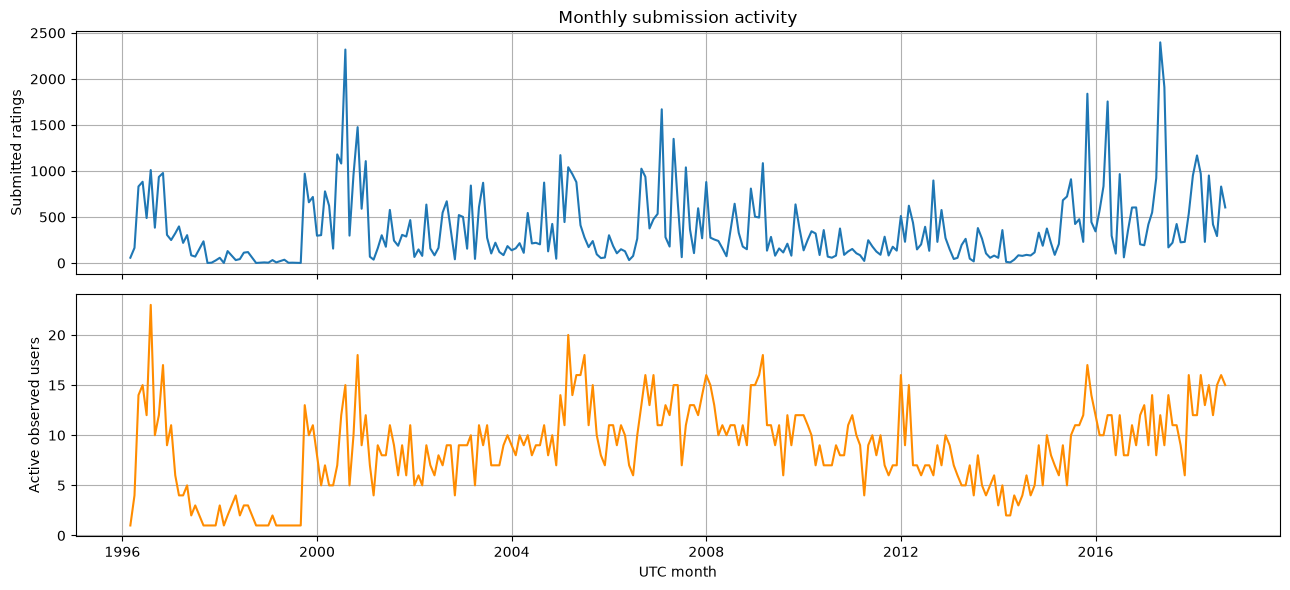

In [9]:
monthly = con.sql("""
SELECT date_trunc('month', to_timestamp(timestamp)) AS month,
       count(*) AS ratings, count(DISTINCT userId) AS active_users,
       count(*) FILTER (WHERE rating >= 4) AS positives
FROM ratings GROUP BY month ORDER BY month
""").df()
display(monthly.head())
print("Submission range UTC:", quality["timestamp_min_utc"], "→", quality["timestamp_max_utc"])
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
axes[0].plot(monthly.month, monthly.ratings)
axes[0].set(ylabel="Submitted ratings", title="Monthly submission activity")
axes[1].plot(monthly.month, monthly.active_users, color="darkorange")
axes[1].set(ylabel="Active observed users", xlabel="UTC month")
plt.tight_layout(); plt.show()

## 7. Rating bursts, adjacent gaps and user spans

Within a user, sort by `(timestamp, movieId)` only to make tied timestamps deterministic. The movie-ID order is **not** evidence of within-second viewing/submission order. Adjacent-gap denominators exclude each user's first event. A 30-minute threshold defines an exploratory **submission session**, not a validated consumption session.

,seconds,adjacent_pairs_at_most,adjacent_pair_denominator,fraction
0,0,15790,100226,0.157544
1,1,17671,100226,0.176312
2,5,36215,100226,0.361333
3,60,83398,100226,0.832099
4,300,92041,100226,0.918335
5,1800,93691,100226,0.934797
6,3600,93876,100226,0.936643
7,86400,95515,100226,0.952996


,seconds,users_at_most,users,fraction
0,0,0,610,0.000000
1,3600,292,610,0.478689
2,86400,362,610,0.593443
3,604800,412,610,0.675410
4,2592000,447,610,0.732787


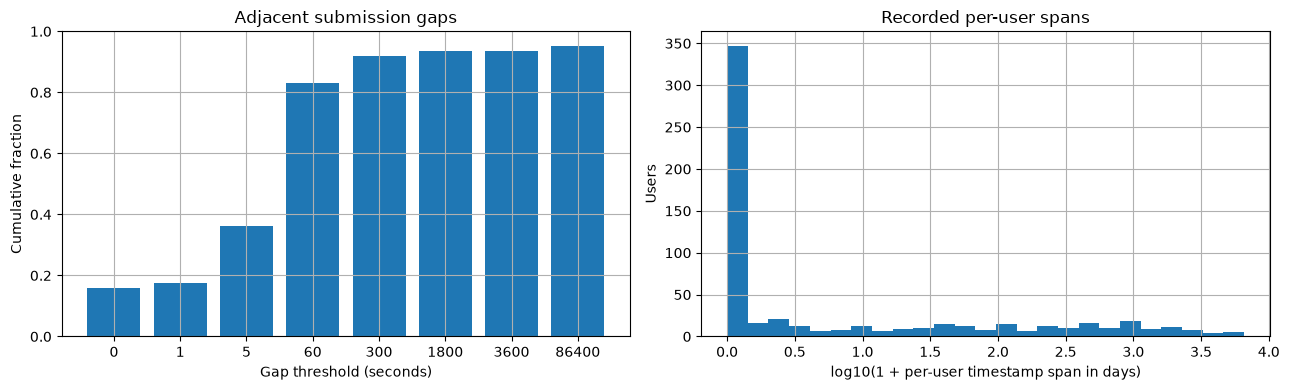

In [10]:
con.execute("""
CREATE OR REPLACE TEMP VIEW submission_gaps AS
SELECT userId, movieId, timestamp,
       timestamp - lag(timestamp) OVER (PARTITION BY userId ORDER BY timestamp, movieId) AS gap_seconds
FROM ratings
""")
gap_thresholds = con.sql("""
WITH thresholds(seconds) AS (VALUES (0),(1),(5),(60),(300),(1800),(3600),(86400))
SELECT seconds, count(*) FILTER (WHERE gap_seconds <= seconds) AS adjacent_pairs_at_most,
       count(gap_seconds) AS adjacent_pair_denominator,
       count(*) FILTER (WHERE gap_seconds <= seconds) * 1.0 / count(gap_seconds) AS fraction
FROM submission_gaps CROSS JOIN thresholds GROUP BY seconds ORDER BY seconds
""").df()
display(gap_thresholds)
assert int(gap_thresholds.adjacent_pair_denominator.iloc[0]) == quality["ratings"] - quality["users"]
span_thresholds = con.sql("""
WITH thresholds(seconds) AS (VALUES (0),(3600),(86400),(604800),(2592000))
SELECT seconds, count(*) FILTER (WHERE span_seconds <= seconds) AS users_at_most,
       count(*) AS users, count(*) FILTER (WHERE span_seconds <= seconds) * 1.0 / count(*) AS fraction
FROM user_activity CROSS JOIN thresholds GROUP BY seconds ORDER BY seconds
""").df()
display(span_thresholds)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(gap_thresholds.seconds.astype(str), gap_thresholds.fraction)
axes[0].set(xlabel="Gap threshold (seconds)", ylabel="Cumulative fraction", ylim=(0, 1), title="Adjacent submission gaps")
axes[1].hist(np.log10(1 + users.span_seconds / 86400), bins=25)
axes[1].set(xlabel="log10(1 + per-user timestamp span in days)", ylabel="Users", title="Recorded per-user spans")
plt.tight_layout(); plt.show()

In [11]:
con.execute("""
CREATE OR REPLACE TEMP VIEW submission_sessions AS
WITH boundaries AS (
 SELECT *, CASE WHEN gap_seconds IS NULL OR gap_seconds > 1800 THEN 1 ELSE 0 END AS new_session
 FROM submission_gaps
), numbered AS (
 SELECT *, sum(new_session) OVER (PARTITION BY userId ORDER BY timestamp, movieId ROWS UNBOUNDED PRECEDING) AS session_id
 FROM boundaries
)
SELECT userId, session_id, count(*) AS ratings, min(timestamp) AS start_timestamp,
       max(timestamp)-min(timestamp) AS span_seconds
FROM numbered GROUP BY userId, session_id
""")
sessions = con.sql("SELECT * FROM submission_sessions ORDER BY ratings DESC, userId, session_id").df()
display(sessions.head(10))
session_summary = con.sql("""
WITH per_user AS (
 SELECT userId, count(*) AS sessions, max(ratings) AS largest_session FROM submission_sessions GROUP BY userId
)
SELECT count(*) AS users, count(*) FILTER (WHERE sessions=1) AS single_submission_session_users,
       median(sessions) AS median_sessions_per_user,
       avg(largest_session * 1.0 / a.n_ratings) AS mean_largest_session_rating_fraction
FROM per_user JOIN user_activity a USING(userId)
""").df()
display(session_summary)

,userId,session_id,ratings,start_timestamp,span_seconds
0,599,5.0,1019,1498513719,20113
1,610,2.0,866,1493843863,6700
2,19,1.0,703,965701107,11775
3,480,1.0,613,1179159558,7256
4,68,1.0,546,1158530999,4930
5,414,2.0,540,961512311,6782
6,89,1.0,518,1520408265,1393
7,561,1.0,505,1491090690,5121
8,525,1.0,500,1476475797,6794
9,217,2.0,499,955940533,5106


,users,single_submission_session_users,median_sessions_per_user,mean_largest_session_rating_fraction
0,610,307,1.0,0.796618


## 8. Exploratory chronological split alternatives — not frozen

Compare three rolling calendar-window alternatives and discrete timestamp 80/10/10 quantiles. Calendar windows are anchored at UTC midnight immediately after the last observed date. All equal timestamps stay together: Train is `< validation_start`; Validation is `[validation_start, test_start)`; prospective Test is `[test_start, end)`.

Every alternative constructs its catalog and histories **only from its Train prefix**. The exploratory eligibility convention is Train-observed items, excluding every Train-rated movie for that user. Future observed positives are then label-side counts only. Display all future users, including those with zero positives or no eligible positives, and distinguish no Train ratings from no Train positives.

These are feasibility views, not saved assignments or final Train/Validation/Test Parquet. Candidate-pool recall and model performance are not measurable without later retrieval experiments. Looking at these aggregate label counts is protocol exploration, not Test-based hyperparameter tuning; freeze the chosen protocol and restrict subsequent Test access before model work.

In [12]:
options = cutoff_options(con)
display(pd.DataFrame(options))
split_summary, split_cohorts, internal_feasibility = split_feasibility(con, options)
display(split_summary)
display(split_cohorts)
for option in options:
    rows = split_summary[split_summary.alternative.eq(option["alternative"])]
    assert int(rows.history_rows.iloc[0] + rows.future_rows.sum()) == quality["ratings"]
    assert rows.eligible_positive.le(rows.future_positive).all()
    assert rows.eligible_users.le(rows.future_users).all()

,alternative,validation_start,test_start,end_exclusive,definition
0,calendar_3m_3m,1521936000,1529884800,1537833600,3-month Validation then 3-month Test; rolling ...
1,calendar_6m_6m,1506297600,1521936000,1537833600,6-month Validation then 6-month Test; rolling ...
2,calendar_6m_12m,1490400000,1506297600,1537833600,6-month Validation then 12-month Test; rolling...
3,timestamp_80_10_10,1458635171,1498029450,1537833600,Observed timestamp 80th/90th discrete quantile...


,alternative,window,train_end_exclusive_utc,label_start_utc,label_end_exclusive_utc,history_rows,history_users,history_items,history_positive,future_rows,future_users,future_positive,eligible_positive,positive_not_train_known,positive_seen_train,train_known_positive_coverage,eligible_positive_fraction,eligible_users,eligible_users_ge5_train_positive,users_without_train_ratings,users_without_positive_history,future_users_without_positive,future_users_without_eligible_positive,users_crossing_boundary_within_30m
0,calendar_3m_3m,validation,2018-03-25T00:00:00+00:00,2018-03-25T00:00:00+00:00,2018-06-25T00:00:00+00:00,97438,589,9378,46856,1403,25,599,488,111,0,0.814691,0.814691,22,16,6,6,1,3,0
1,calendar_3m_3m,test,2018-03-25T00:00:00+00:00,2018-06-25T00:00:00+00:00,2018-09-25T00:00:00+00:00,97438,589,9378,46856,1995,29,1125,1015,110,0,0.902222,0.902222,28,11,17,17,1,1,0
2,calendar_6m_6m,validation,2017-09-25T00:00:00+00:00,2017-09-25T00:00:00+00:00,2018-03-25T00:00:00+00:00,93249,575,8766,45210,4189,34,1646,1346,300,0,0.817740,0.817740,33,18,14,14,1,1,0
3,calendar_6m_6m,test,2017-09-25T00:00:00+00:00,2018-03-25T00:00:00+00:00,2018-09-25T00:00:00+00:00,93249,575,8766,45210,3398,40,1724,1452,272,0,0.842227,0.842227,39,15,24,24,1,1,0
4,calendar_6m_12m,validation,2017-03-25T00:00:00+00:00,2017-03-25T00:00:00+00:00,2017-09-25T00:00:00+00:00,87371,554,8371,42892,5878,37,2318,2213,105,0,0.954702,0.954702,36,15,21,21,0,1,0
5,calendar_6m_12m,test,2017-03-25T00:00:00+00:00,2017-09-25T00:00:00+00:00,2018-09-25T00:00:00+00:00,87371,554,8371,42892,7587,60,3370,2702,668,0,0.801780,0.801780,59,20,39,39,1,1,0
6,timestamp_80_10_10,validation,2016-03-22T08:26:11+00:00,2016-03-22T08:26:11+00:00,2017-06-21T07:17:30+00:00,80668,522,7867,39254,10084,62,5198,4810,388,0,0.925356,0.925356,62,21,41,41,0,0,1
7,timestamp_80_10_10,test,2016-03-22T08:26:11+00:00,2017-06-21T07:17:30+00:00,2018-09-25T00:00:00+00:00,80668,522,7867,39254,10084,74,4128,3233,895,0,0.783188,0.783188,72,18,54,54,2,2,0


,exploratory_cohort,users,future_positive,eligible_positive,eligible_users,alternative,window
0,cold_positive_history,6,209,202,6,calendar_3m_3m,validation
1,moderate_5_19,3,33,33,2,calendar_3m_3m,validation
2,warm_20_plus,16,357,253,14,calendar_3m_3m,validation
3,cold_positive_history,17,1028,957,17,calendar_3m_3m,test
4,moderate_5_19,2,9,9,2,calendar_3m_3m,test
5,warm_20_plus,10,88,49,9,calendar_3m_3m,test
6,cold_positive_history,14,1156,927,14,calendar_6m_6m,validation
7,moderate_5_19,2,52,52,2,calendar_6m_6m,validation
8,sparse_1_4,1,18,18,1,calendar_6m_6m,validation
9,warm_20_plus,17,420,349,16,calendar_6m_6m,validation


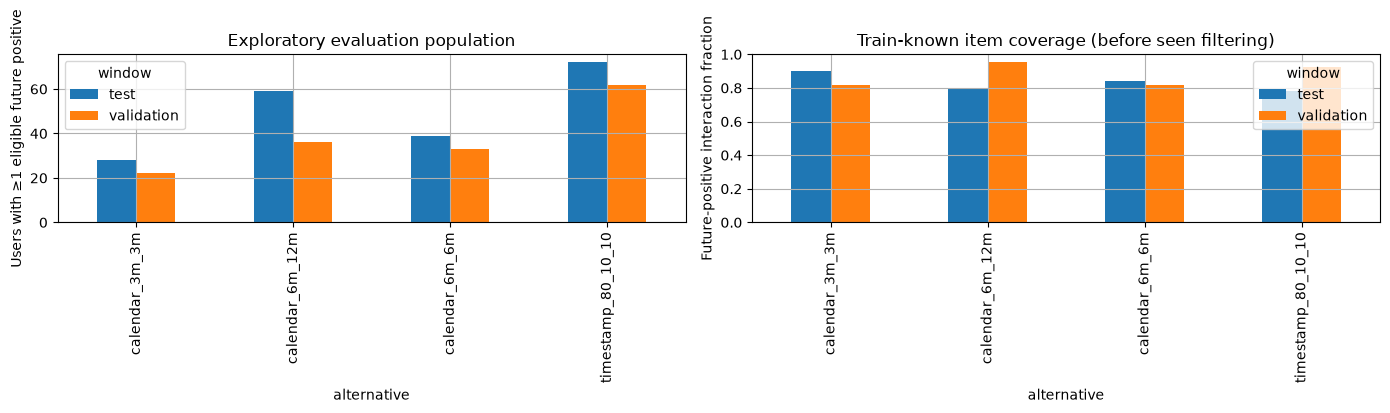

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
split_summary.pivot(index="alternative", columns="window", values="eligible_users").plot.bar(ax=axes[0])
axes[0].set(ylabel="Users with ≥1 eligible future positive", title="Exploratory evaluation population")
split_summary.pivot(index="alternative", columns="window", values="train_known_positive_coverage").plot.bar(ax=axes[1], ylim=(0, 1))
axes[1].set(ylabel="Future-positive interaction fraction", title="Train-known item coverage (before seen filtering)")
plt.tight_layout(); plt.show()

## 9. Internal ranker-label feasibility and burst sensitivity

For each outer-Train candidate protocol, inspect an earlier prefix using its own observed 80th-percentile timestamp. Snapshot fitting would use timestamps strictly before that internal cutoff; potential ranking labels would occur from that cutoff up to the outer Validation start. No retriever snapshot, candidate pool, sampled contrast or ranking example is generated now.

`potential_ranker_queries_upper_bound` counts users with at least one catalog-eligible later positive. It is **not** the effective LambdaMART query count: future retrieval must recover a positive and offer useful contrast. Snapshot/full-Train feature distribution mismatch must later be measured. A user spanning a boundary within 30 minutes may have one submission burst bisected even when exact timestamp ties are preserved; inspect such cases or test a prespecified embargo sensitivity before freezing a protocol.

In [14]:
display(internal_feasibility)
burst_boundary_cases = split_summary[["alternative", "window", "users_crossing_boundary_within_30m"]]
display(burst_boundary_cases)

,alternative,status,snapshot_end_exclusive_utc,internal_labels_end_exclusive_utc,potential_ranker_queries_upper_bound,history_rows,history_users,history_items,history_positive,future_rows,future_users,future_positive,eligible_positive,positive_not_train_known,positive_seen_train,train_known_positive_coverage,eligible_positive_fraction,eligible_users,eligible_users_ge5_train_positive,users_without_train_ratings,users_without_positive_history,future_users_without_positive,future_users_without_eligible_positive,users_crossing_boundary_within_30m
0,calendar_3m_3m,exploratory; no candidates or training example...,2015-11-08T19:29:26+00:00,2018-03-25T00:00:00+00:00,108,77950,504,7701,38138,19488,108,8718,7580,1138,0,0.869465,0.869465,108,23,85,85,0,0,0
1,calendar_6m_6m,exploratory; no candidates or training example...,2015-06-28T20:52:21+00:00,2017-09-25T00:00:00+00:00,104,74599,484,7482,36498,18650,104,8712,7786,926,0,0.893710,0.893710,104,13,91,91,0,0,1
2,calendar_6m_12m,exploratory; no candidates or training example...,2013-01-26T05:20:33+00:00,2017-03-25T00:00:00+00:00,125,69896,448,6981,33915,17475,125,8977,7324,1653,0,0.815863,0.815863,125,19,106,106,0,0,1
3,timestamp_80_10_10,exploratory; no candidates or training example...,2011-09-05T17:39:26+00:00,2016-03-22T08:26:11+00:00,124,64534,416,6577,31037,16134,126,8217,6728,1489,0,0.818790,0.818790,124,19,106,106,2,2,1


,alternative,window,users_crossing_boundary_within_30m
0,calendar_3m_3m,validation,0
1,calendar_3m_3m,test,0
2,calendar_6m_6m,validation,0
3,calendar_6m_6m,test,0
4,calendar_6m_12m,validation,0
5,calendar_6m_12m,test,0
6,timestamp_80_10_10,validation,1
7,timestamp_80_10_10,test,0


## 10. Implications for the six retrievers and LambdaMART

| Component | Data-driven implication to carry forward |
|---|---|
| Popularity | Necessary explicit cold-history baseline; counts must come from the selected Train prefix. Report how often other channels fall back to it. |
| Genre CBF | Useful when positive collaborative history is short, but needs a Train-only profile; no-genres movies need a declared fallback. Genres are coarse and multi-label. |
| ItemCF | Long-tail co-occurrences will be weak; use sparse bounded neighbors and retain complete permitted user history. Filter observed low and high Train ratings alike. |
| Implicit ALS | Separate positive, observed-low and missing confidence conventions. Sparse/cold users and cold items require explicit treatment, not implied learned factors. |
| LightGCN | CPU sizing must be bounded on the Small graph; preserve chronological positive edges and reject observed pairs when drawing unknown contrasts. An empty-history user has no learned collaborative evidence. |
| Hybrid Two-Tower | Build ID/genre/history features at the training cutoff. New user IDs cannot be treated as trained IDs; genres do not solve an absent user profile. |
| RRF | Requires compatible candidate budgets/catalogs/query populations; raw scores are not calibrated. Measure union recall before attributing improvements to ranking. |
| LambdaMART | Use genuinely out-of-time retrieval features inside outer Train. Count recovered-positive/contrast queries, sampled unknowns, empty queries and pool ceilings. No-positive pools cannot train informative ranking groups. |

All findings concern recovery of future observed submissions. No exposure logs, online CTR or causal satisfaction are measured. User-selection, popularity/exposure bias, burst submissions and changing populations limit generalization.

In [15]:
# Construct a recommendation from observed feasibility, not model scores. Nothing is frozen.
primary_name = "timestamp_80_10_10"
primary = split_summary[split_summary.alternative.eq(primary_name)].set_index("window")
primary_internal = internal_feasibility[internal_feasibility.alternative.eq(primary_name)].iloc[0]
cold_test = int(primary.loc["test", "users_without_train_ratings"])
total_test_users = int(primary.loc["test", "future_users"])
recommendation = (
    f"Propose the tie-preserving global timestamp 80/10/10 alternative for the next phase: "
    f"it retains {int(primary.loc['validation', 'future_rows']):,} Validation and "
    f"{int(primary.loc['test', 'future_rows']):,} prospective Test ratings, with "
    f"{int(primary.loc['validation', 'eligible_users'])} / {int(primary.loc['test', 'eligible_users'])} "
    f"catalog-eligible positive queries. However, {cold_test}/{total_test_users} Test-window users have no Train ratings. "
    f"Only {int(primary.loc['validation', 'eligible_users_ge5_train_positive'])} / "
    f"{int(primary.loc['test', 'eligible_users_ge5_train_positive'])} queries have at least five Train positives. "
    f"Report all eligible users and cold/sparse/warm cohorts separately, with a prespecified warm-history secondary analysis; "
    f"do not hide the cold-user majority. The internal snapshot diagnostic has only "
    f"{int(primary_internal['potential_ranker_queries_upper_bound'])} potential ranking queries before candidate recall/contrast losses. "
    f"Keep the 6-month Validation / 12-month Test calendar alternative as a temporal sensitivity analysis, "
    f"and inspect burst crossings or a prespecified embargo. If personalized estimates remain too small, "
    f"consider an approved expanding-window backtest rather than a random split or silent user exclusion. "
    f"Record a protocol decision before generating final splits. No models were fitted or compared here."
)
display(Markdown("**Proposed next-phase protocol (not frozen):** " + recommendation))

**Proposed next-phase protocol (not frozen):** Propose the tie-preserving global timestamp 80/10/10 alternative for the next phase: it retains 10,084 Validation and 10,084 prospective Test ratings, with 62 / 72 catalog-eligible positive queries. However, 54/74 Test-window users have no Train ratings. Only 21 / 18 queries have at least five Train positives. Report all eligible users and cold/sparse/warm cohorts separately, with a prespecified warm-history secondary analysis; do not hide the cold-user majority. The internal snapshot diagnostic has only 124 potential ranking queries before candidate recall/contrast losses. Keep the 6-month Validation / 12-month Test calendar alternative as a temporal sensitivity analysis, and inspect burst crossings or a prespecified embargo. If personalized estimates remain too small, consider an approved expanding-window backtest rather than a random split or silent user exclusion. Record a protocol decision before generating final splits. No models were fitted or compared here.

## 11. Execution record and immutable inputs

The notebook closes its in-memory DuckDB connection and rechecks all source hashes. No persistent database, Parquet split, training run or data-versioning system is created. The manifest is machine-readable acquisition evidence, and all tables/figures above are computed from the downloaded files during actual execution.

In [16]:
verify_provenance(DATA_DIR)
print("Input hashes reverified; raw files unchanged.")
print("DuckDB:", duckdb.__version__)
print("Figures were displayed inline. No model fitting, final splits, DVC, MLflow or deployment occurred.")
con.close()

Input hashes reverified; raw files unchanged.
DuckDB: 1.5.2
Figures were displayed inline. No model fitting, final splits, DVC, MLflow or deployment occurred.
